In [1]:
import xarray as xr
import numpy as np
from scipy.ndimage import zoom

# Compare different land-sea masks

This notebook, shows three different land-sea masks that are used in three different workflows:

* "LLN2F1.nc": this mask is used within the ICOADS-internal quality control workflow
* "LASE_V11": this mask is used within the DWD-internal quality control tool "VALIDAT"
* "osm_land_mask.nc": this mask is used within the DWD-internal VOS-GDAC workflow

The goal of this notebook is to determine which mask we should use within the GLAMOD project.

## "LLN2F1.nc": The ICOADS-internal land-sea mask

We downloaded the control file from [icoads.noaa.gov](https://web.archive.org/web/20161210130640/http://icoads.noaa.gov/mask.html) and converted it to a netCDF file using CDO: ``cdo -f nc import_binary LLN2F1.ctl LLN2F1.nc``.

The file contains three flags: `0` denotes a grid cell at sea, `1` a grid cell on land and `2` a grid cell at the coast.

We read the data usin `xarray` and make it CF-compliant:

* Convert longitude from [0, 360] to [-180, 180]
* Treat grid cells at the coast as grid cells on land

The ICOADS land-sea mask has a spatial resolution of 2°.

In [2]:
time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)
ds_icoads = xr.open_dataset("LLN2F1.nc", decode_times=time_coder)
ds_icoads = ds_icoads.assign_coords(lon=(((ds_icoads.lon + 180) % 360) - 180)).sortby("lon")
ds_icoads = ds_icoads.rename(lat="latitude", lon="longitude", land="lsm")
ds_icoads["lsm"] = ds_icoads.lsm.where(ds_icoads.lsm != 2, other=1)
ds_icoads["lsm"] = ds_icoads.lsm.astype(np.int8)
ds_icoads = ds_icoads.squeeze(drop=True)
ds_icoads

<xarray.Dataset> Size: 18kB
Dimensions:    (latitude: 90, longitude: 180)
Coordinates:
  * latitude   (latitude) float64 720B 89.0 87.0 85.0 83.0 ... -85.0 -87.0 -89.0
  * longitude  (longitude) float64 1kB -179.0 -177.0 -175.0 ... 177.0 179.0
Data variables:
    lsm        (latitude, longitude) int8 16kB 0 0 0 0 0 0 0 0 ... 1 1 1 1 1 1 1
Attributes:
    CDI:          Climate Data Interface version 2.5.2 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    history:      Tue Nov 03 12:28:49 2026: cdo -f nc import_binary LLN2F1.ct...
    CDO:          Climate Data Operators version 2.5.2 (https://mpimet.mpg.de...

Now, we can plot the ICOADS land-sea mask.

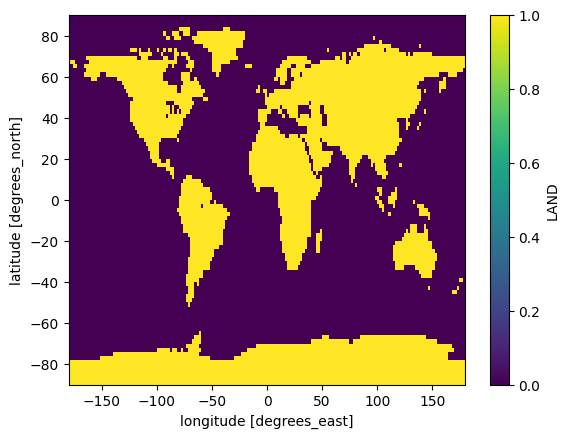

In [3]:
ds_icoads.lsm.plot()

## "LASE_V11": The DWD-internal "VALIDAT" land-sea mask

The original mask is an ASCII file consisting of a single string containing the characters `0` and `1`. Each character represent a latitude-longitude cell. `0` denotes a grid cell at sea, `1` a grid cell on land. The string begins in the north-west (latitude=89.995°N, longitude=-179.995°E) and runs eastwards. After 36,000 characters (latitude=89.995°N, longitude=179.995°E), it jumps again to the west but one grid cell further south (latitude=89.985, longitude=-179.995), and so on. This means the "VALIDAT" land-sea mask has a spatial resolution of 0.01°.  

Firstly, we have to read this string, transform it to a `numpy.array` and convert it to a CF-compliant `xarray.Dataset`.

In [4]:
with open("LASE_V11", "r", encoding="utf-8") as f:
    lase = f.read()

In [5]:
nlon = 36000
ntotal = len(lase)
nlat = int(ntotal / nlon)

In [6]:
mask = np.frombuffer(lase.encode("ascii"), dtype=np.int8) - ord("0")
mask = mask.reshape(nlat, nlon)

In [7]:
latitudes = 90 - (np.arange(nlat) + 0.5) * (180 / nlat)
longitudes = -180 + (np.arange(nlon) + 0.5) * (360 / nlon)

In [8]:
ds_validat = xr.Dataset(
    data_vars = {
        "lsm": (
            ("latitude", "longitude"), 
            mask.astype(np.uint8),
            {
                "standard_name": "land_binary_mask",
                "long_name": "Land-sea mask",
                "flag_values": np.array([0, 1], dtype=np.uint8),
                "flag_meanings": "sea land",
            },
        )
    },
    coords = {
        "latitude": (
            "latitude", 
            latitudes,
            {
                "standard_name": "latitude",
                "long_name": "latitude",
                "units": "degrees_north",
                "axis": "Y",
            },
        ),
        "longitude": (
            "longitude", 
            longitudes,
            {
                "standard_name": "longitude",
                "long_name": "longitude",
                "units": "degrees_east",
                "axis": "X",
            },
        ),
    },
    attrs = {
        "Conventions": "CF-1.10",
        "title": "Land-sea mask",
        "insitution": "Deutscher Wetterdienst",
        "source": "ASCII validat land-sea mask LASE_V11",
    }
)
ds_validat

<xarray.Dataset> Size: 648MB
Dimensions:    (latitude: 18000, longitude: 36000)
Coordinates:
  * latitude   (latitude) float64 144kB 90.0 89.98 89.97 ... -89.97 -89.99 -90.0
  * longitude  (longitude) float64 288kB -180.0 -180.0 -180.0 ... 180.0 180.0
Data variables:
    lsm        (latitude, longitude) uint8 648MB 0 0 0 0 0 0 0 ... 1 1 1 1 1 1 1
Attributes:
    Conventions:  CF-1.10
    title:        Land-sea mask
    insitution:   Deutscher Wetterdienst
    source:       ASCII validat land-sea mask LASE_V11

Now, we can plot the VALIDAT land-sea mask:

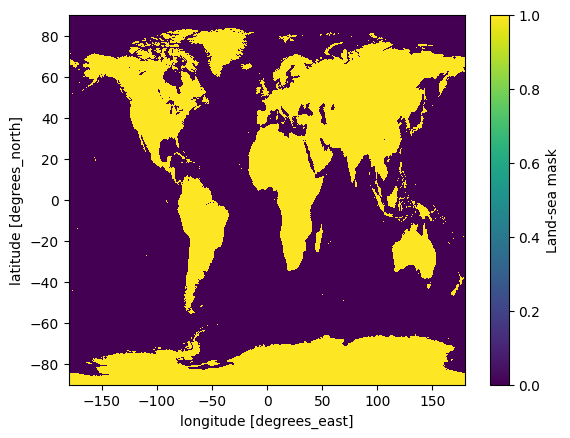

In [9]:
ds_validat.lsm.isel(
    latitude=slice(None, None, 10),
    longitude=slice(None, None, 10)
).plot()

We store the mask on disk as a precaution.

In [10]:
ds_validat.to_netcdf("LASE_V11.nc", encoding={"lsm": {"zlib": True, "complevel": 4}})

## "osm_land_mask.nc": The DWD-internal VOS-GDAC mask

This mask was created with OpenStreetMap. We can simply read this land-sea mask using `xarray`:

In [11]:
ds_osm = xr.open_dataset("osm_land_mask.nc")
ds_osm = ds_osm.rename(lat="latitude", lon="longitude", land="lsm")
ds_osm["lsm"] = ds_osm.lsm.astype(np.int8)
ds_osm = ds_osm.isel(latitude=slice(None, None, -1))
ds_osm

<xarray.Dataset> Size: 934MB
Dimensions:    (latitude: 21600, longitude: 43200)
Coordinates:
  * latitude   (latitude) float64 173kB 90.0 89.99 89.98 ... -89.98 -89.99 -90.0
  * longitude  (longitude) float64 346kB -180.0 -180.0 -180.0 ... 180.0 180.0
Data variables:
    lsm        (latitude, longitude) int8 933MB 0 0 0 0 0 0 0 ... 1 1 1 1 1 1 1
Attributes:
    Conventions:        CF-1.8
    title:              Global 30 arc-second land mask, navigable inland wate...
    source:             OpenStreetMap land polygons (land-polygons-split-4326...
    waterways:          Suez Canal (canal, added 2026-08): artificial sea-goi...
    license:            OpenStreetMap data (c) OpenStreetMap contributors, OD...
    rule_rivers:        HydroRIVERS rivers >= 6500 m3/s are water along their...
    rule_estuaries:     HydroRIVERS rivers >= 500 m3/s are water within 75 km...
    rule_lakes:         HydroLAKES lakes >= 500 km2 are water; no ship traffi...
    recommended_use:    Treat a position as inland when it lies more than 25 ...
    known_limitations:  Rivers are carved 1-3 cells wide along their HydroRIV...
    history:            2026-11-04: rasterised from the sources above
    evaluation:         Tuned on the VOS-GDAC archive 1996-2026, 41.1 million...

The VOS-GDAC land-sea mask has a spatial resolution of 0.00833°. We can plot the mask:

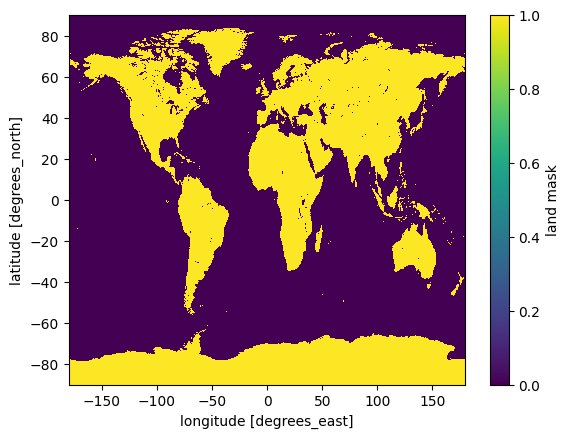

In [12]:
ds_osm.lsm.isel(
    latitude=slice(None, None, 10),
    longitude=slice(None, None, 10)
).plot()

## Compare the three land-sea mask

For an comparision of the three land-sea mask, we map the masks to the finest spatial resolution ("VOS-GDAC": 0.00833°).

In [13]:
def expand_coarse_grid(grid_fine, grid_coarse):
    nlat_fine = len(grid_fine.latitude)
    nlon_fine = len(grid_fine.longitude)
    nlat_coarse = len(grid_coarse.latitude)
    nlon_coarse = len(grid_coarse.longitude)    
    fac_lat = nlat_fine / nlat_coarse
    fac_lon = nlon_fine / nlon_coarse
    mask = grid_coarse["lsm"].values
    expanded = zoom(mask, (fac_lat, fac_lon), order=0)
    grid_expanded = grid_fine.copy()
    grid_expanded["lsm"].values = expanded
    return grid_expanded

In [14]:
ds_icoads_fine = expand_coarse_grid(ds_osm, ds_icoads)

In [15]:
ds_validat_fine = expand_coarse_grid(ds_osm, ds_validat)    

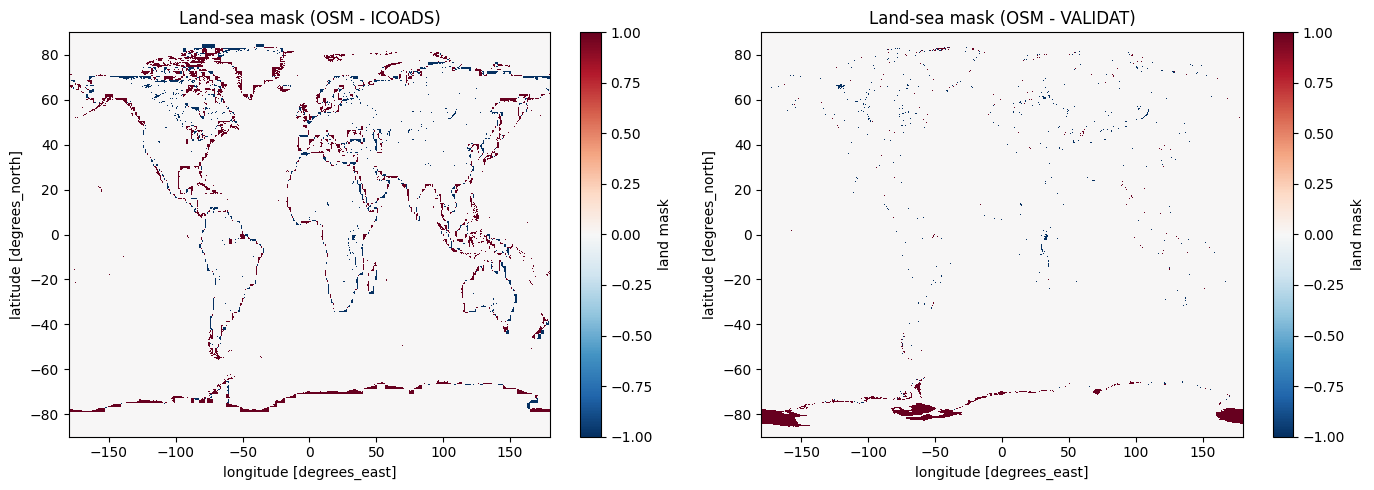

In [16]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
lsm_icoads = ds_icoads_fine.lsm
lsm_validat = ds_validat_fine.lsm
lsm_osm = ds_osm.lsm
lsm_diff_icoads = lsm_osm - lsm_icoads
lsm_diff_validat = lsm_osm - lsm_validat
data_arrays = [
    lsm_diff_icoads, 
    lsm_diff_validat,
]
titles = [
    "Land-sea mask (OSM - ICOADS)", 
    "Land-sea mask (OSM - VALIDAT)",
]
for ax, da, title in zip(axes.flat, data_arrays, titles):
    da.isel(
        latitude=slice(None, None, 10),
        longitude=slice(None, None, 10)
    ).plot(ax=ax)
    ax.set_title(title)

plt.tight_layout()
plt.show()    

Here is some room for discussions now ...